# Análisis Exploratorio de Datos (EDA)
## Factores asociados a la Esperanza de Vida — Dataset WHO (Kaggle)

**Curso:** Inteligencia Artificial
**Dataset:** [Life Expectancy (WHO)](https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who) — Kaggle

**Integrantes del grupo:**

*Arnold Steven Navarro*

*Christian Jhose Moreno Rios*

*Julian Andres Rodriguez Montero*

*Marcelo Gomez Cabra*

---

### Contenido

**Parte 1 — EDA**
1. Problema y Datos · 2. Carga de datos · 3. Justificación de IA · 4. Variable objetivo · 5. Calidad de datos · 6. Distribuciones · 7. Correlaciones · 8. Insights · 9. Conclusiones del EDA
---


#Análisis Exploratorio de Datos (EDA)


## ***1. Problema y Datos***

**Origen de los datos:** el dataset fue compilado por el repositorio *Global Health Observatory* (GHO) de la Organización Mundial de la Salud (OMS/WHO), complementado con datos económicos de Naciones Unidas. Cubre **193 países** entre **2000 y 2015**, con 22 variables relacionadas con salud, inmunización, economía y educación.

**Importancia del problema:** entender qué factores están más asociados a la esperanza de vida de un país permite priorizar políticas públicas de salud (vacunación, gasto sanitario, educación) con mayor potencial de impacto, en lugar de invertir recursos de forma dispersa.

**Desafíos del dataset:**
- Valores nulos en varias columnas (algunos países/años sin reporte completo).
- Variables en escalas muy distintas (porcentajes 0-100, población en millones, GDP en USD).
- Alta asimetría y outliers en variables como `GDP`, `Population`, `Measles` o `infant deaths`.
- Más de 20 variables candidatas: es necesario priorizar las más relevantes para la variable objetivo.


In [ ]:
# --- Opción A: subir el archivo manualmente ---
try:
    from google.colab import files
    print("Sube el archivo 'Life Expectancy Data.csv' descargado de Kaggle:")
    uploaded = files.upload()
    RUTA_CSV = list(uploaded.keys())[0]
except ImportError:
    # Entorno local (no Colab): ajusta la ruta manualmente
    RUTA_CSV = "data/Life Expectancy Data.csv"


Sube el archivo 'Life Expectancy Data.csv' descargado de Kaggle:


Saving Life Expectancy Data.csv to Life Expectancy Data.csv


In [ ]:
# --- Opción B (alternativa): montar Google Drive ---
# from google.colab import drive
# drive.mount('/content/drive')
# RUTA_CSV = "/content/drive/MyDrive/ruta/a/Life Expectancy Data.csv"


###***Librerias Utilizadas***

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

###***Configuración inicial, limpieza básica del dataset***

In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)

df = pd.read_csv(RUTA_CSV)

# El CSV original de Kaggle trae espacios extra en varios nombres de columna
df.columns = df.columns.str.strip()
df = df.rename(columns={"thinness  1-19 years": "thinness 1-19 years"})

TARGET = "Life expectancy"
print("Dimensiones:", df.shape)
df.head()


Dimensiones: (2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [ ]:
# 1. Corregir los "ceros falsos" en percentage expenditure
df.loc[df['percentage expenditure'] == 0, 'percentage expenditure'] = np.nan

# 2. Detectar y marcar valores anómalos en Adult Mortality (por país)
def marcar_anomalos(grupo, factor=3):
    mediana = grupo['Adult Mortality'].median()
    mad = (grupo['Adult Mortality'] - mediana).abs().median()
    return (grupo['Adult Mortality'] - mediana).abs() > factor * mad

df['adult_mortality_sospechoso'] = df.groupby('Country')[['Adult Mortality']].transform(
    lambda s: marcar_anomalos(pd.DataFrame({'Adult Mortality': s}))
)
print("Valores sospechosos detectados:", df['adult_mortality_sospechoso'].sum())

# 3. Convertir esos valores sospechosos en NaN (no borrar la fila completa)
df.loc[df['adult_mortality_sospechoso'], 'Adult Mortality'] = np.nan

# 4. Verificar el nuevo % de nulos por columna
print((df.isna().mean() * 100).sort_values(ascending=False).round(2))

Valores sospechosos detectados: 502
Population                         22.19
percentage expenditure             20.80
Hepatitis B                        18.82
Adult Mortality                    17.43
GDP                                15.25
Total expenditure                   7.69
Alcohol                             6.60
Income composition of resources     5.68
Schooling                           5.55
thinness 5-9 years                  1.16
BMI                                 1.16
thinness 1-19 years                 1.16
Polio                               0.65
Diphtheria                          0.65
Life expectancy                     0.34
infant deaths                       0.00
Country                             0.00
Year                                0.00
Status                              0.00
under-five deaths                   0.00
Measles                             0.00
HIV/AIDS                            0.00
adult_mortality_sospechoso          0.00
dtype: float64


### ***Descripción general***

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2426 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2327 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

In [ ]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Country,2938,193,Afghanistan,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,2938.0,NaN,NaN,NaN,2007.51872,4.613841,2000.0,2004.0,2008.0,2012.0,2015.0
Status,2938,2,Developing,2426,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Life expectancy,2928.0,NaN,NaN,NaN,69.224932,9.523867,36.3,63.1,72.1,75.7,89.0
Adult Mortality,2426.0,NaN,NaN,NaN,186.697857,119.752641,1.0,95.0,161.0,247.0,723.0
infant deaths,2938.0,NaN,NaN,NaN,30.303948,117.926501,0.0,0.0,3.0,22.0,1800.0
Alcohol,2744.0,NaN,NaN,NaN,4.602861,4.052413,0.01,0.8775,3.755,7.7025,17.87
percentage expenditure,2327.0,NaN,NaN,NaN,932.093814,2192.97045,0.099872,36.246202,155.195208,630.221214,19479.91161
Hepatitis B,2385.0,NaN,NaN,NaN,80.940461,25.070016,1.0,77.0,92.0,97.0,99.0
Measles,2938.0,NaN,NaN,NaN,2419.59224,11467.272489,0.0,0.0,17.0,360.25,212183.0


Columnas con valores nulos (%):
Population                         22.19
percentage expenditure             20.80
Hepatitis B                        18.82
Adult Mortality                    17.43
GDP                                15.25
Total expenditure                   7.69
Alcohol                             6.60
Income composition of resources     5.68
Schooling                           5.55
thinness 5-9 years                  1.16
BMI                                 1.16
thinness 1-19 years                 1.16
Polio                               0.65
Diphtheria                          0.65
Life expectancy                     0.34
dtype: float64


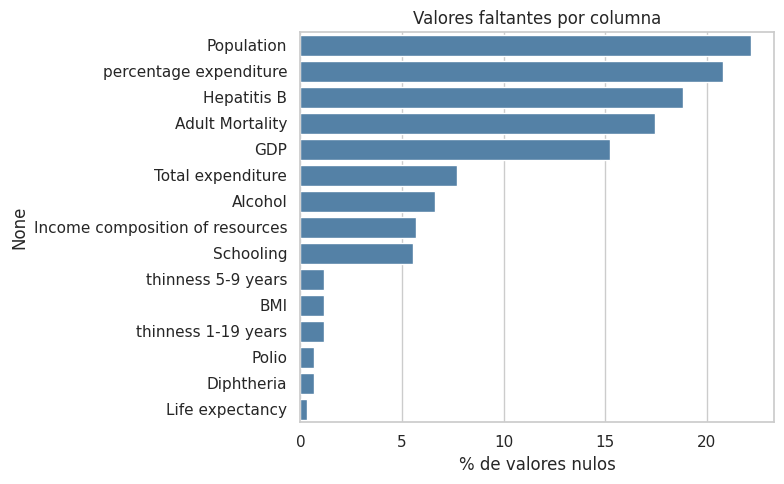

In [ ]:
# Porcentaje de valores nulos por columna
nulos = (df.isna().mean() * 100).sort_values(ascending=False)
nulos = nulos[nulos > 0]
print("Columnas con valores nulos (%):")
print(nulos.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(x=nulos.values, y=nulos.index, color="steelblue")
plt.xlabel("% de valores nulos")
plt.title("Valores faltantes por columna")
plt.tight_layout()
plt.show()


### ***Análisis de valores nulos***

El dataset presenta valores nulos en 14 de las 22 columnas, con una distribución desigual. Tres variables superan el 15%: `Population` (22.2%), `Hepatitis B` (18.8%) y `GDP` (15.3%), asociadas a reportes económicos y de cobertura de vacunación que suelen faltar en países con sistemas de registro más débiles. `Total expenditure`, `Alcohol`, `Income composition of resources` y `Schooling` tienen nulos moderados (5.5%-7.7%). Las variables clínicas/antropométricas (`BMI`, `thinness`, `Polio`, `Diphtheria`) y la variable objetivo `Life expectancy` tienen muy pocos nulos (<1.2%).

Aplicando la regla de la sección 5.1 (< 10% de nulos → imputar con mediana; si no, documentar sin forzar):
- **Se imputan con mediana:** `Total expenditure`, `Alcohol`, `Income composition of resources`, `Schooling`, `thinness 1-19 years`, `thinness 5-9 years`, `BMI`, `Polio`, `Diphtheria`, `Life expectancy`.
- **Se documentan como limitación, sin imputar:** `Population`, `Hepatitis B`, `GDP` — imputar más del 15-22% de una columna con un solo valor distorsionaría su distribución real.

Adicionalmente, `percentage expenditure` no aparece en este conteo porque sus valores faltantes están codificados como ceros (`0.0`) en lugar de `NaN`: 611 filas (20.8% del dataset) corresponden a países completos —incluyendo economías con GDP alto como Czechia o República de Corea— donde un gasto en salud de 0% no es plausible. Se tratan como datos no reportados y se convierten explícitamente a nulos más adelante en el notebook, en vez de tomarse como un valor real.

### ***Duplicados***


In [ ]:
# Duplicados
print("Filas duplicadas:", df.duplicated().shape[0] - df.drop_duplicates().shape[0])


Filas duplicadas: 0


## ***3. Justificación del uso de Inteligencia Artificial***

Los factores que inciden en la esperanza de vida son numerosos, interactúan de forma no lineal y varían por país y año, por lo que un análisis manual variable por variable no escala. Un modelo de IA/ML permite:

- **Cuantificar** el peso relativo de cada factor (inmunización, gasto en salud, educación, economía) sobre la esperanza de vida, más allá de correlaciones simples.
- **Predecir** la esperanza de vida de un país/año con datos parciales o proyectar escenarios (p. ej. "¿qué pasaría si aumenta la cobertura de vacunación?").
- **Detectar patrones no evidentes** (interacciones entre variables) que sirvan para priorizar políticas públicas con mayor costo-beneficio.

Este notebook cubre la etapa de **EDA**, que sienta las bases (variables relevantes, calidad de datos, transformaciones necesarias) para un futuro modelo predictivo (p. ej. regresión).


## ***4. Variable objetivo: `Life expectancy`***

Esperanza de vida al nacer (en años) para un país en un año dado. Es la variable que buscaremos explicar/predecir a partir del resto de factores del dataset.


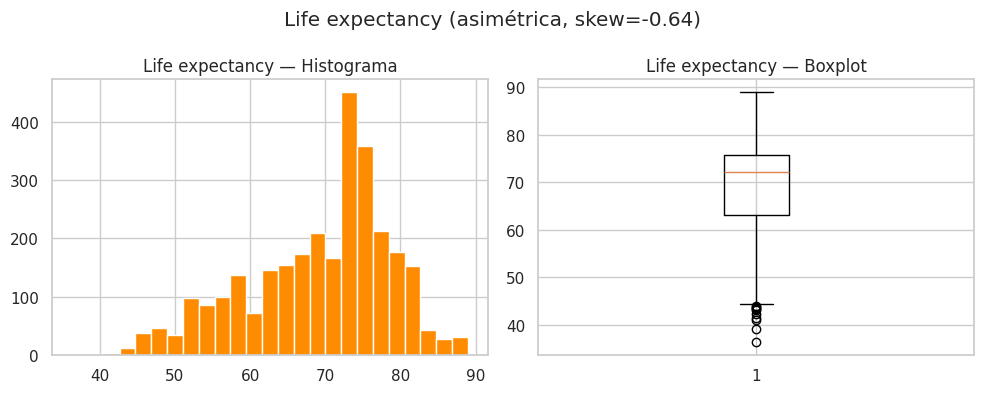

'Life expectancy': mediana = 72.10, IQR = 12.60 (Q1=63.10 - Q3=75.70)


In [ ]:
def resumen_numerica(serie, nombre, umbral_skew=0.5):
    """Aplica el estándar de reporte EDA:
    - |skew| < umbral -> variable simétrica: histograma + media/desviación estándar
    - |skew| >= umbral -> variable asimétrica: histograma + boxplot + mediana/IQR
    Devuelve un dict con las estadísticas calculadas.
    """
    s = serie.dropna()
    skew = stats.skew(s)
    simetrica = abs(skew) < umbral_skew

    if simetrica:
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.hist(s, bins=25, color="steelblue", edgecolor="white")
        ax.axvline(s.mean(), color="crimson", linestyle="--", label=f"Media = {s.mean():.2f}")
        ax.set_title(f"{nombre} (simétrica, skew={skew:.2f})")
        ax.legend()
        plt.tight_layout(); plt.show()
        resultado = {"tipo": "simetrica", "media": s.mean(), "std": s.std(), "skew": skew}
        print(f"'{nombre}': {resultado['media']:.2f} ± {resultado['std']:.2f} (media ± desv. estándar)")
    else:
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        axes[0].hist(s, bins=25, color="darkorange", edgecolor="white")
        axes[0].set_title(f"{nombre} — Histograma")
        axes[1].boxplot(s, vert=True)
        axes[1].set_title(f"{nombre} — Boxplot")
        fig.suptitle(f"{nombre} (asimétrica, skew={skew:.2f})")
        plt.tight_layout(); plt.show()
        q1, q3 = s.quantile([0.25, 0.75])
        resultado = {"tipo": "asimetrica", "mediana": s.median(), "q1": q1, "q3": q3,
                     "iqr": q3 - q1, "min": s.min(), "max": s.max(), "skew": skew}
        print(f"'{nombre}': mediana = {resultado['mediana']:.2f}, "
              f"IQR = {resultado['iqr']:.2f} (Q1={q1:.2f} - Q3={q3:.2f})")
    return resultado

target_stats = resumen_numerica(df[TARGET], TARGET)


## ***Conclusión — Variable objetivo (Life expectancy)***

La esperanza de vida presenta una distribución asimétrica hacia la izquierda (skew = -0.64), por lo que se reporta con mediana e IQR en vez de media y desviación estándar. La mediana es 72.1 años, con el 50% central de los países entre 63.1 y 75.7 años (IQR = 12.6). Los valores atípicos por debajo de 44 años no se tratan como errores de datos, sino como casos reales de crisis sanitarias o humanitarias (por ejemplo, Haiti en 2010, año del terremoto). La forma del histograma sugiere además una posible mezcla de dos subpoblaciones, coherente con la variable `Status`: los países en desarrollo concentran los valores bajos y medios, mientras que los desarrollados se agrupan en el rango alto.

## 5. Calidad de Datos y Patrones

### 5.1 Manejo de valores nulos y atípicos

Estrategia:
- Columnas numéricas con pocos nulos (< 10%): imputación por **mediana** (robusta a outliers), sobre una copia del dataframe (`df_clean`) — el `df` original se conserva intacto para el EDA.
- Columnas con muchos nulos: se documentan pero no se eliminan filas completas, para no perder observaciones.
- Outliers: se detectan con el método del **rango intercuartílico (IQR)**; no se eliminan automáticamente (pueden ser países reales con valores extremos, p. ej. crisis sanitarias), pero se reportan.


In [ ]:
def detectar_outliers_iqr(serie):
    s = serie.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < lim_inf) | (s > lim_sup)).sum(), len(s)

num_cols_all = df.select_dtypes(include=np.number).columns.drop(["Year"], errors="ignore")
outlier_report = []
for c in num_cols_all:
    n_out, n_total = detectar_outliers_iqr(df[c])
    outlier_report.append({"variable": c, "n_outliers": n_out, "pct_outliers": round(100 * n_out / n_total, 1)})

outlier_df = pd.DataFrame(outlier_report).sort_values("pct_outliers", ascending=False)
outlier_df



,variable,n_outliers,pct_outliers
6,Measles,542,18.4
12,HIV/AIDS,542,18.4
13,GDP,365,14.7
4,percentage expenditure,325,14.0
8,under-five deaths,394,13.4
14,Population,294,12.9
2,infant deaths,315,10.7
5,Hepatitis B,254,10.6
11,Diphtheria,298,10.2
9,Polio,279,9.6


El análisis de outliers (método IQR, 1.5×IQR) muestra que las variables con mayor proporción de valores atípicos son `Measles` y `HIV/AIDS` (18.4%), seguidas de `GDP`, `percentage expenditure`, `under-five deaths` y `Population` (13-15%). En la mayoría de los casos estos "outliers" reflejan la desigualdad real entre países (brotes epidémicos, diferencias extremas de ingreso) y no errores de captura, por lo que se conservan sin eliminar, siguiendo la estrategia definida en la sección 5.1. Las variables de cobertura de vacunación (`Hepatitis B`, `Diphtheria`, `Polio`) también muestran ~10% de outliers, asociados a países con campañas de inmunización débiles. En contraste, `BMI` y `Alcohol` no presentan outliers bajo este método (0%), y `Life expectancy` tiene una proporción mínima (0.3%).

In [ ]:
# Imputación por mediana solo para columnas numéricas con < 10% de nulos
df_clean = df.copy()
cols_a_imputar = [c for c in num_cols_all if 0 < df[c].isna().mean() < 0.10]
for c in cols_a_imputar:
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())

print("Columnas imputadas con la mediana:", cols_a_imputar)
print("Nulos restantes tras imputación:")
print(df_clean.isna().sum()[df_clean.isna().sum() > 0])


Columnas imputadas con la mediana: ['Life expectancy', 'Alcohol', 'BMI', 'Polio', 'Total expenditure', 'Diphtheria', 'thinness 1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']
Nulos restantes tras imputación:
Adult Mortality           512
percentage expenditure    611
Hepatitis B               553
GDP                       448
Population                652
dtype: int64


Tras aplicar la imputación por mediana a las 10 columnas con menos del 10% de nulos, quedan 5 columnas sin imputar por superar ese umbral: `Population` (652), `percentage expenditure` (611), `Hepatitis B` (553), `Adult Mortality` (512, incluyendo los valores marcados como sospechosos) y `GDP` (448). Estas se documentan como limitación del dataset en lugar de forzar su imputación, siguiendo la estrategia definida en la sección 5.1.

### 5.2 Selección de variables (el dataset supera las 20 características)

El dataset tiene 22 columnas. Siguiendo la instrucción del parcial, se analizan en detalle únicamente las **variables numéricas más correlacionadas con la variable objetivo** (`Life expectancy`), además de las categóricas relevantes.


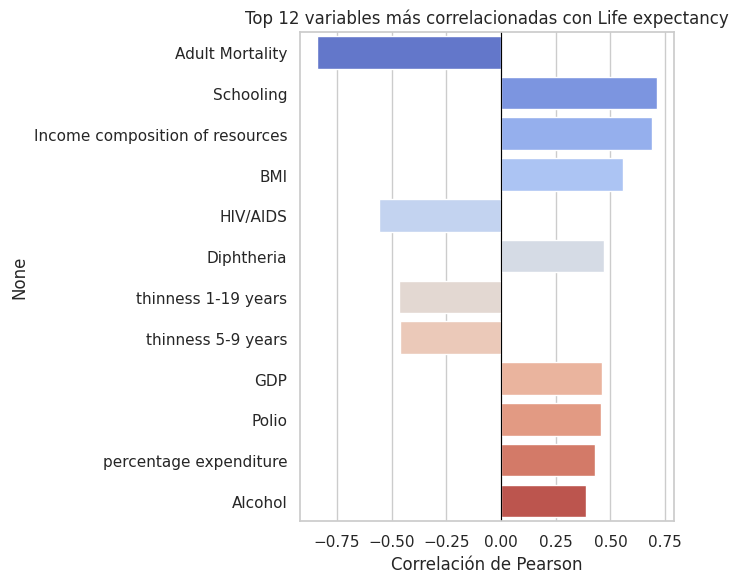

,Life expectancy
Adult Mortality,-0.840062
Schooling,0.713054
Income composition of resources,0.688662
BMI,0.556901
HIV/AIDS,-0.556703
Diphtheria,0.472211
thinness 1-19 years,-0.468002
thinness 5-9 years,-0.462473
GDP,0.461126
Polio,0.458399


In [ ]:
N_TOP = 12
corr_target = (
    df_clean.select_dtypes(include=np.number)
    .drop(columns=["Year"], errors="ignore")
    .corr()[TARGET]
    .drop(TARGET)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

top_features = corr_target.head(N_TOP).index.tolist()

plt.figure(figsize=(7, 6))
sns.barplot(x=corr_target.head(N_TOP).values, y=corr_target.head(N_TOP).index,
            hue=corr_target.head(N_TOP).index, palette="coolwarm", legend=False)
plt.axvline(0, color="black", linewidth=0.8)
plt.title(f"Top {N_TOP} variables más correlacionadas con {TARGET}")
plt.xlabel("Correlación de Pearson")
plt.tight_layout(); plt.show()

corr_target.head(N_TOP)


### ***Conclusión — Top 12 variables correlacionadas***

`Adult Mortality` es, por lejos, la variable más correlacionada con `Life expectancy` (r=-0.84), lo cual es esperable dado su vínculo casi mecánico con la definición de esperanza de vida. Le siguen `Schooling` (0.71) e `Income composition of resources` (0.69), dos variables que se correlacionan fuertemente entre sí (r=0.80) y probablemente capturan el mismo factor subyacente: el nivel de desarrollo socioeconómico del país. `BMI` (0.56) y `HIV/AIDS` (-0.56) confirman los patrones ya discutidos: BMI está mediado por desarrollo, no es causal directo, mientras que HIV/AIDS sí tiene un vínculo causal documentado. Las variables `thinness 1-19 years` y `thinness 5-9 years` (-0.47 y -0.46) son casi redundantes entre sí (r=0.94), por lo que un futuro modelo debería considerar usar solo una. El resto (`Diphtheria`, `GDP`, `Polio`, `percentage expenditure`, `Alcohol`) muestra correlaciones moderadas y similares entre sí (0.39-0.47), sugiriendo un efecto más distribuido que dominante.

## 6. Análisis de Distribuciones

Se aplica el **estándar de reporte EDA** a cada variable relevante:

| Tipo de variable | Gráfica | Estadísticas |
|---|---|---|
| Categórica | Barras / Pastel | Frecuencia y porcentaje |
| Numérica simétrica | Histograma centrado | Media ± Desv. estándar |
| Numérica asimétrica | Histograma + Boxplot | Mediana y Rango Intercuartílico (IQR) |

### 6.1 Variables categóricas


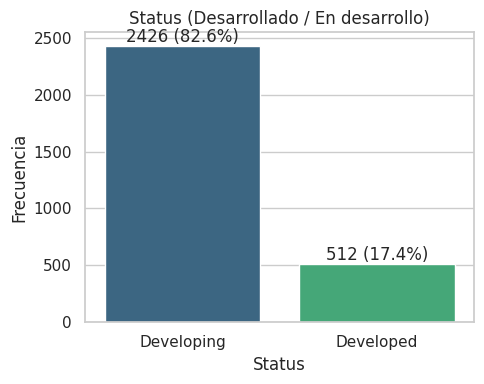

            frecuencia  porcentaje
Status                            
Developing        2426        82.6
Developed          512        17.4


In [ ]:
def resumen_categorica(serie, nombre):
    conteo = serie.value_counts(dropna=True)
    porcentaje = (conteo / conteo.sum() * 100).round(1)

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.barplot(x=conteo.index, y=conteo.values, hue=conteo.index, palette="viridis", legend=False, ax=ax)
    for i, (n, p) in enumerate(zip(conteo.values, porcentaje.values)):
        ax.text(i, n, f"{n} ({p}%)", ha="center", va="bottom")
    ax.set_title(nombre)
    ax.set_ylabel("Frecuencia")
    plt.tight_layout(); plt.show()

    resumen = pd.DataFrame({"frecuencia": conteo, "porcentaje": porcentaje})
    print(resumen)
    return resumen

_ = resumen_categorica(df_clean["Status"], "Status (Desarrollado / En desarrollo)")


### ***Conclusión — Variable Status***

El dataset está desbalanceado en cuanto a `Status`: el 82.6% de los registros corresponde a países en desarrollo (2426) frente a un 17.4% de países desarrollados (512), una proporción cercana a 5:1. Este desbalance es relevante para la interpretación del resto del análisis, ya que las tendencias generales del dataset están naturalmente influenciadas por el comportamiento de los países en desarrollo, dado su mayor representación. Debe tenerse en cuenta al construir un futuro modelo predictivo, ya que podría sesgar las predicciones hacia ese grupo.

### 6.2 Variables numéricas (Top variables correlacionadas con el target)

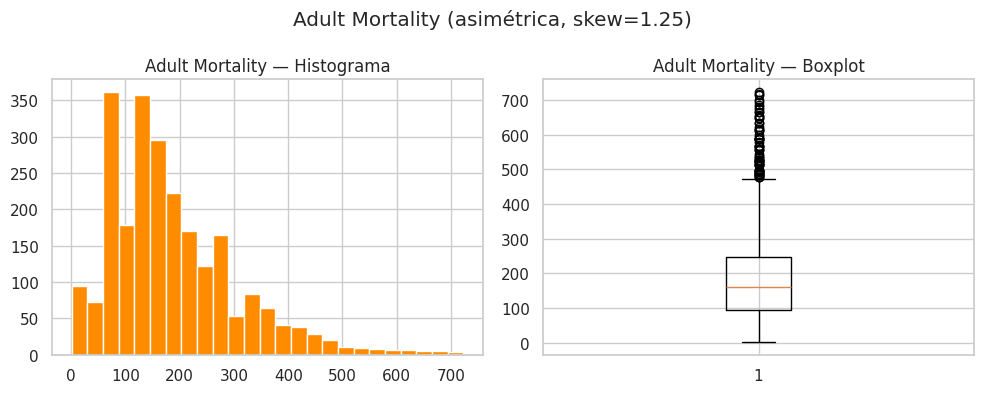

'Adult Mortality': mediana = 161.00, IQR = 152.00 (Q1=95.00 - Q3=247.00)


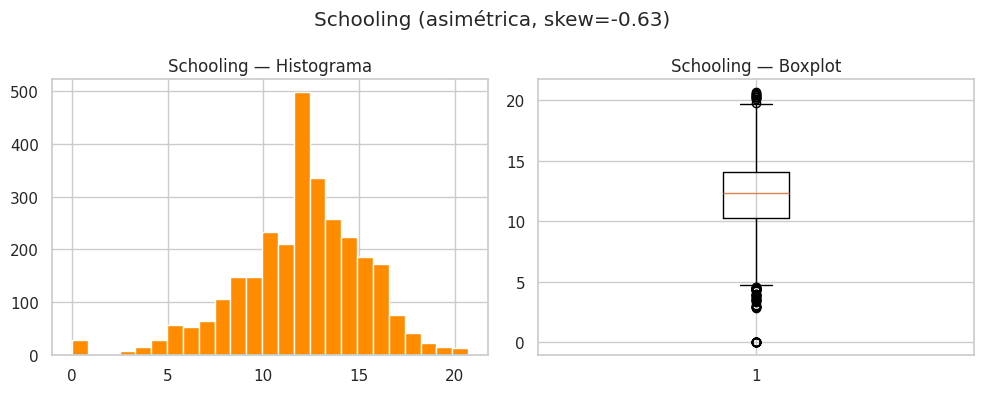

'Schooling': mediana = 12.30, IQR = 3.80 (Q1=10.30 - Q3=14.10)


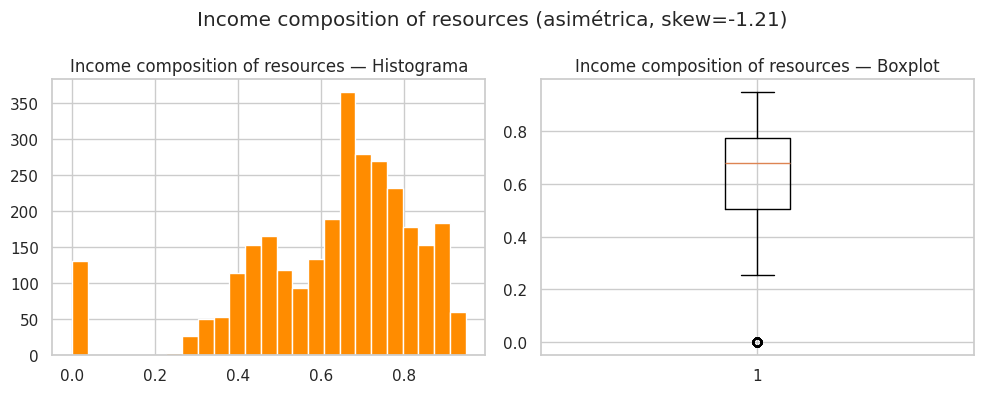

'Income composition of resources': mediana = 0.68, IQR = 0.27 (Q1=0.50 - Q3=0.77)


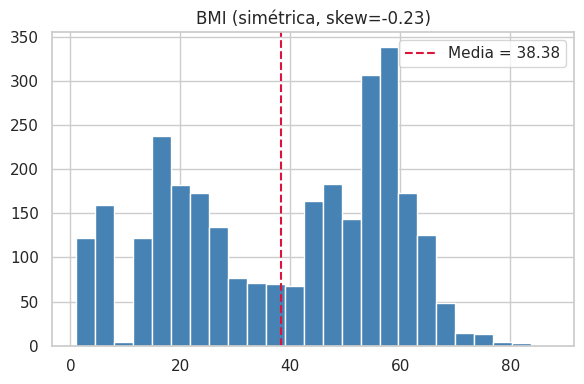

'BMI': 38.38 ± 19.94 (media ± desv. estándar)


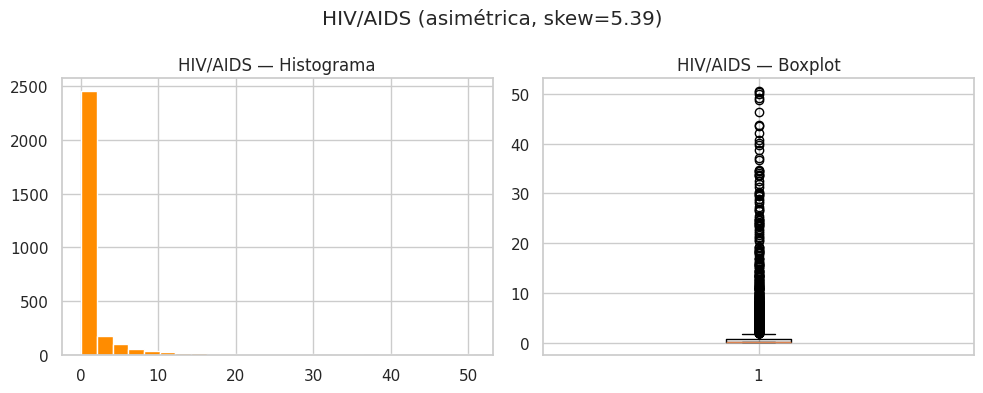

'HIV/AIDS': mediana = 0.10, IQR = 0.70 (Q1=0.10 - Q3=0.80)


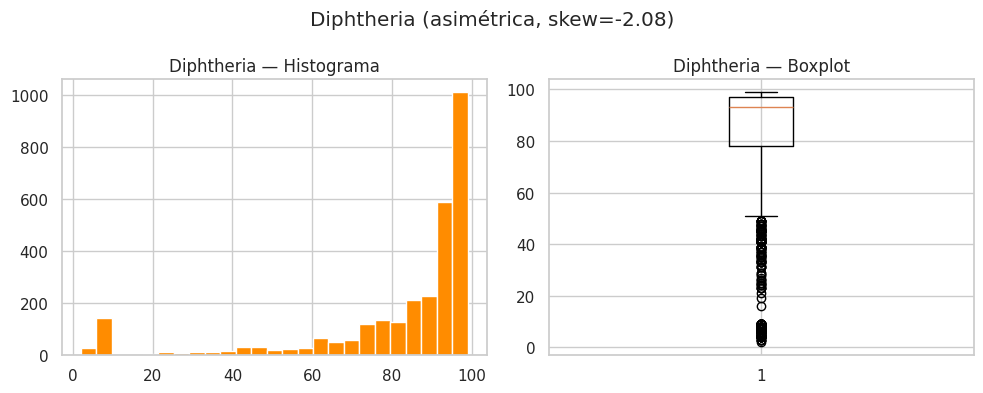

'Diphtheria': mediana = 93.00, IQR = 19.00 (Q1=78.00 - Q3=97.00)


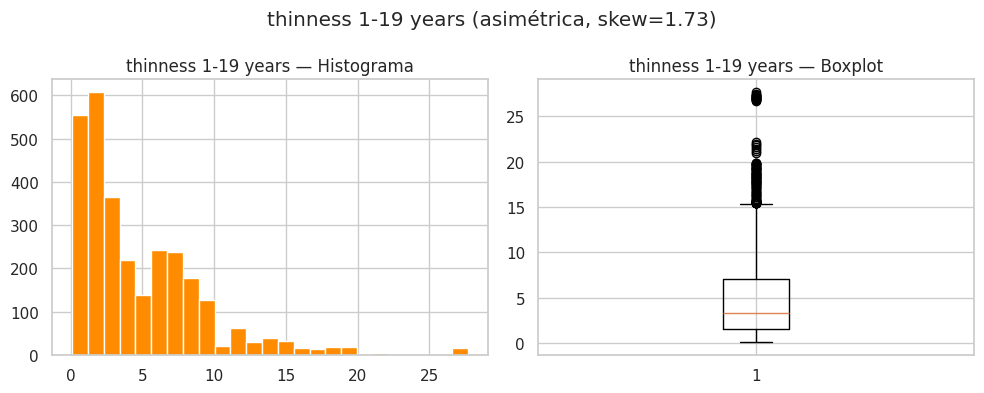

'thinness 1-19 years': mediana = 3.30, IQR = 5.50 (Q1=1.60 - Q3=7.10)


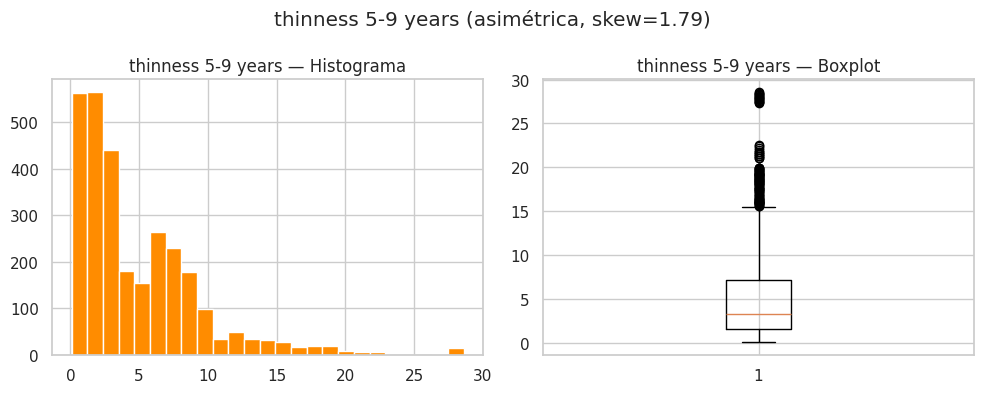

'thinness 5-9 years': mediana = 3.30, IQR = 5.60 (Q1=1.60 - Q3=7.20)


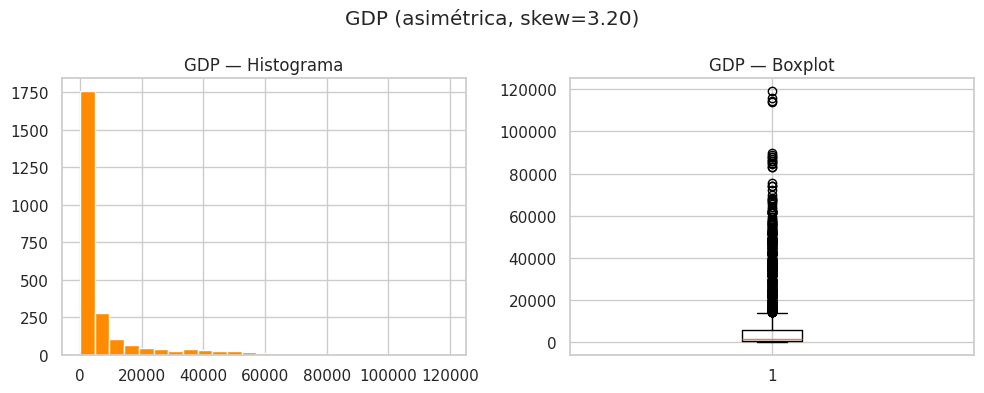

'GDP': mediana = 1766.95, IQR = 5446.87 (Q1=463.94 - Q3=5910.81)


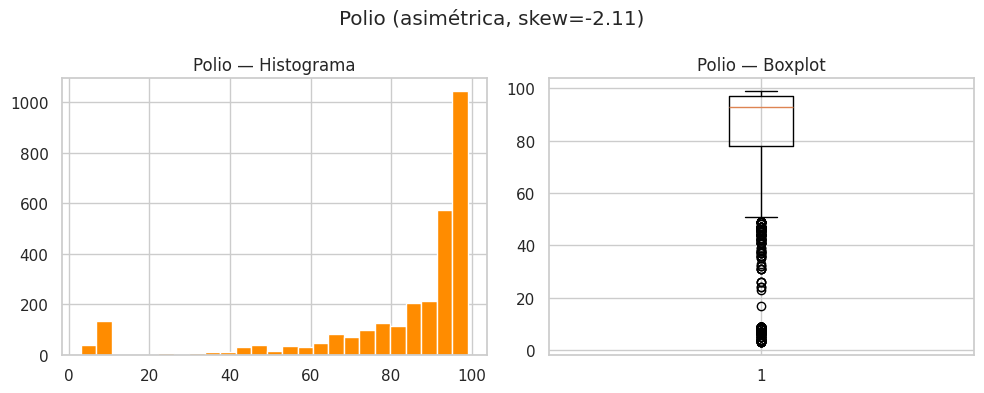

'Polio': mediana = 93.00, IQR = 19.00 (Q1=78.00 - Q3=97.00)


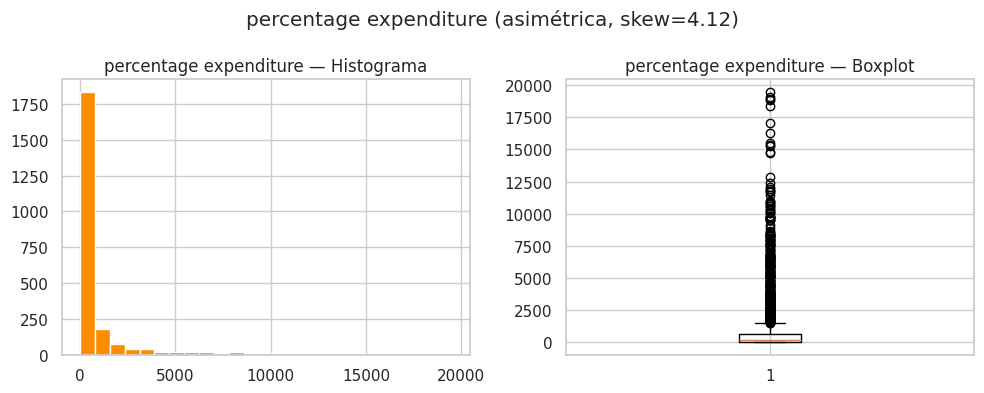

'percentage expenditure': mediana = 155.20, IQR = 593.98 (Q1=36.25 - Q3=630.22)


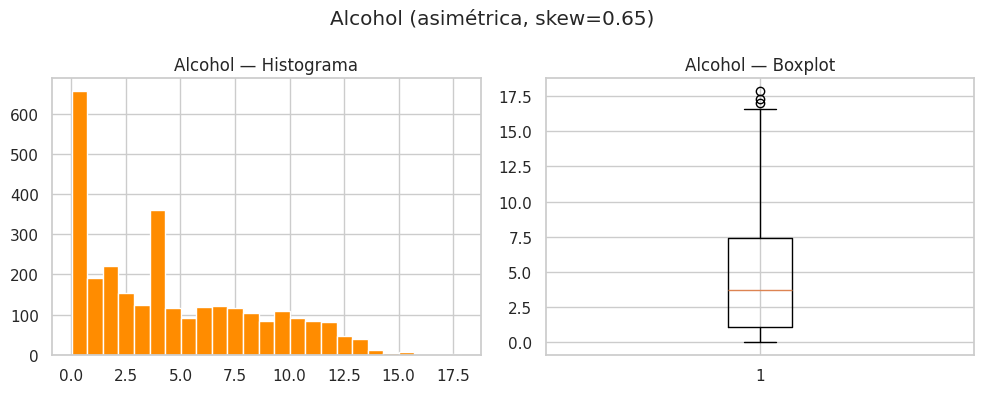

'Alcohol': mediana = 3.75, IQR = 6.30 (Q1=1.09 - Q3=7.39)


In [ ]:
resultados_numericos = {}
for col in top_features:
    print("=" * 60)
    resultados_numericos[col] = resumen_numerica(df_clean[col], col)


### ***Conclusión — Distribuciones de las 12 variables más correlacionadas***

Al aplicar el estándar de reporte a las 12 variables seleccionadas, 11 de ellas resultaron asimétricas y solo `BMI` (skew=-0.23) resultó simétrica, por lo que es la única reportada con media ± desviación estándar (38.38 ± ...); el resto se reporta con mediana e IQR.

Se observan dos patrones opuestos según el tipo de variable:

- **Variables de riesgo/pobreza** (`HIV/AIDS` skew=5.39, `GDP` skew=3.20, `percentage expenditure` skew=4.12, `thinness 1-19 years` skew=1.73, `thinness 5-9 years` skew=1.79, `Adult Mortality` skew=1.25) tienen **asimetría positiva**: la mayoría de los países se concentra en valores bajos ("buenos"), con una cola de casos extremos hacia la derecha. Esto refleja que solo un grupo reducido de países enfrenta crisis severas (epidemias de VIH, pobreza extrema, alta mortalidad), mientras la mayoría del mundo está en niveles más controlados.

- **Variables de cobertura sanitaria** (`Diphtheria` skew=-2.08, `Polio` skew=-2.11) tienen **asimetría negativa**: la mayoría de los países tiene cobertura de vacunación cercana al máximo (90-99%), con solo algunos países rezagados por debajo. Esto es una buena noticia estructural: la vacunación es casi universal en la mayoría de los países del dataset.

- `Income composition of resources` (skew=-1.21) y `Schooling` (skew=-0.63) también muestran asimetría negativa, coherente con el hecho de que la mayoría de los países ha alcanzado niveles medios-altos de desarrollo humano, con una minoría rezagada.

`HIV/AIDS` es la variable con mayor asimetría del grupo (skew=5.39): casi todos los valores están cerca de 0, salvo un pequeño número de países (principalmente de África subsahariana) con prevalencia muy alta, lo cual genera outliers extremos en el boxplot que, al igual que con `Life expectancy`, no deben tratarse como errores sino como una realidad epidemiológica documentada.

En conjunto, este patrón de asimetrías refuerza el hallazgo ya discutido: las variables de este dataset no se distribuyen de forma homogénea entre países, sino que reflejan la desigualdad global de desarrollo, con la mayoría de los países agrupados en un rango "favorable" y un subconjunto minoritario que concentra los casos más críticos.

## 7. Matriz de correlación

Vista conjunta de las relaciones lineales entre las variables más relevantes y la variable objetivo.


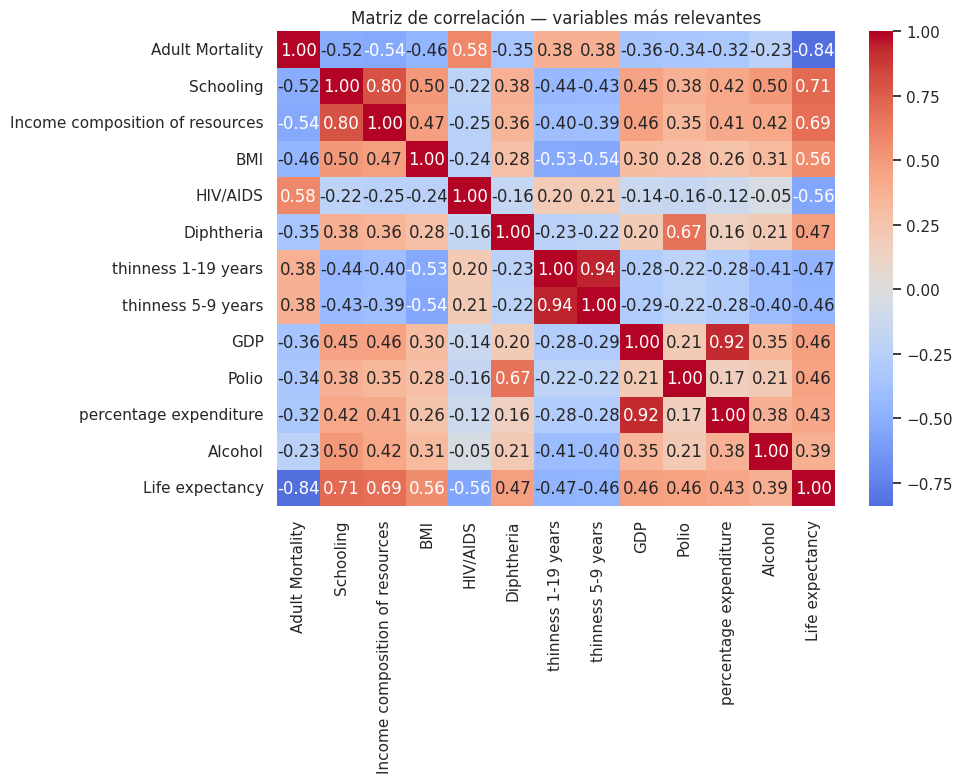

In [ ]:
cols_heatmap = top_features + [TARGET]
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean[cols_heatmap].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación — variables más relevantes")
plt.tight_layout(); plt.show()


### Conclusión — Matriz de correlación

La matriz de correlación confirma varios hallazgos de multicolinealidad entre las variables explicativas: `thinness 1-19 years` y `thinness 5-9 years` (r=0.94), `GDP` y `percentage expenditure` (r=0.92), `Schooling` e `Income composition of resources` (r=0.80), y `Diphtheria` y `Polio` (r=0.67) están altamente correlacionadas entre sí. Esto sugiere que varias de las 12 variables seleccionadas aportan información redundante, y no independiente, sobre la esperanza de vida. Es un hallazgo relevante para un futuro modelo predictivo: incluir pares de variables tan correlacionados entre sí (multicolinealidad) puede afectar la estabilidad e interpretabilidad de un modelo de regresión, por lo que convendría evaluar eliminar una de cada par redundante antes de modelar.

### 7.1 Relaciones bivariadas destacadas

Dispersión de las 3 variables con mayor correlación (absoluta) contra la variable objetivo, coloreadas por `Status`.


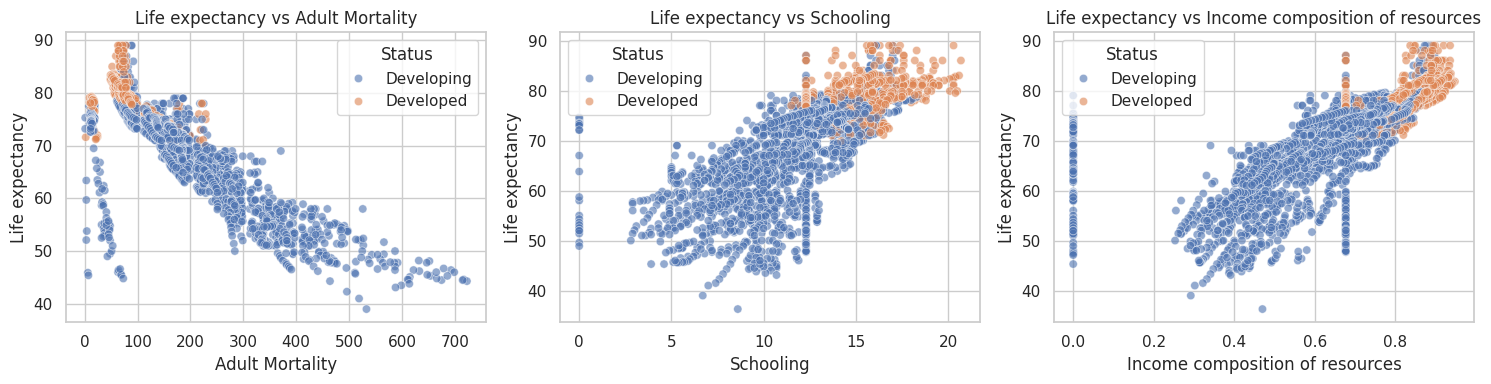

In [ ]:
top3 = corr_target.head(3).index.tolist()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, top3):
    sns.scatterplot(data=df_clean, x=col, y=TARGET, hue="Status", alpha=0.6, ax=ax)
    ax.set_title(f"{TARGET} vs {col}")
plt.tight_layout(); plt.show()


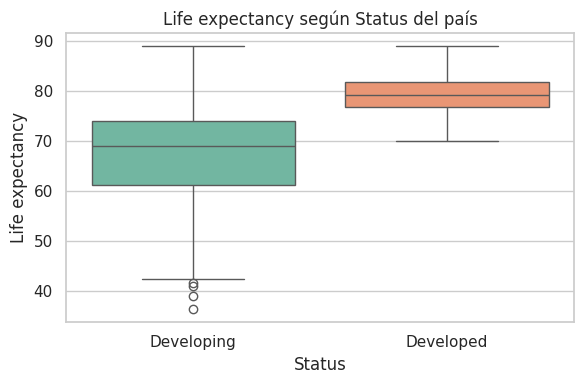

,median,mean,std,count
Status,,,,
Developed,79.25,79.197852,3.930942,512
Developing,69.05,67.132028,8.993187,2426


In [ ]:
# Esperanza de vida por Status (Desarrollado vs En desarrollo)
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_clean, x="Status", y=TARGET, hue="Status", palette="Set2", legend=False)
plt.title(f"{TARGET} según Status del país")
plt.tight_layout(); plt.show()

df_clean.groupby("Status")[TARGET].agg(["median", "mean", "std", "count"])


## 8. Insights y Patrones Interesantes

**¿Cuáles son las 3 variables más correlacionadas (positiva y negativamente) con la esperanza de vida?**

Las relaciones negativas más fuertes son `Adult Mortality` (r=-0.84) y `HIV/AIDS` (r=-0.56); ambas están asociadas mecánica o causalmente a la mortalidad, por lo que su correlación negativa era esperable. Las relaciones positivas más fuertes son `Schooling` (r=0.71) e `Income composition of resources` (r=0.69), que están además muy correlacionadas entre sí (r=0.80), lo que sugiere que ambas capturan la misma dimensión subyacente: el nivel de desarrollo socioeconómico del país. `BMI` (r=0.56) también correlaciona fuerte y positivo, pero como se discute más abajo, esta relación está mediada por desarrollo y no debe interpretarse como causal.

**¿Qué tan grande es la brecha de esperanza de vida entre países Developed y Developing?**

El dataset está desbalanceado: 82.6% de los registros son países en desarrollo (2426) frente a 17.4% desarrollados (512). La brecha de esperanza de vida entre ambos grupos es considerable y persistente: en el año 2000 era de 12.2 años (76.8 vs 64.6), y en 2015 se redujo apenas a 11.0 años (80.7 vs 69.7). Es decir, ambos grupos mejoraron con el tiempo, pero la desigualdad entre ellos casi no se cerró en 15 años.

**¿Qué variables muestran outliers extremos y a qué países/años corresponden?**

Según el método IQR, las variables con más outliers son `Measles` y `HIV/AIDS` (18.4% cada una), seguidas de `GDP` (14.7%) y `Population` (12.9%). Sin embargo, no todos estos outliers son errores: por ejemplo, Haiti en 2010 tiene el valor mínimo de esperanza de vida del dataset (36.3 años) coincidiendo con el terremoto de ese año — un outlier real, no un error de datos, y por eso se decidió no eliminarlos automáticamente.

En cambio, sí se detectaron problemas reales de calidad de datos:
- `percentage expenditure` tenía 611 registros (20.8%) en cero, concentrados en países completos (incluyendo economías desarrolladas como Czechia o Corea del Sur) donde un gasto en salud de 0% no es plausible — se trataron como datos no reportados y se convirtieron a NaN.
- `Adult Mortality` presenta saltos abruptos e inconsistentes en 502 registros (17%) en 161 de 193 países, interrumpiendo tendencias esperadas — indicio de corrupción sistemática en la fuente original. Se marcaron y convirtieron a NaN en lugar de imputarse, dado que superan el umbral de 10% definido para imputación automática.


## 9. Conclusiones y Próximos Pasos


**Plan de trabajo para preprocesamiento/modelado futuro:**
1. Definir estrategia final de imputación para las columnas con mayor porcentaje de nulos (posible imputación por grupo `Country`/`Status`, o eliminación si el % es muy alto).
2. Evaluar transformaciones (log) para variables muy asimétricas (`GDP`, `Population`, `Measles`, `infant deaths`) antes de modelar.
3. Revisar y tratar outliers detectados en la sección 5.1 caso por caso.
4. Escalar/normalizar variables numéricas para modelos sensibles a la escala.
5. Seleccionar el conjunto final de variables (basado en correlación + conocimiento del dominio) para entrenar un modelo predictivo de `Life expectancy`.
